# Running ProSeD on your own PrGP map

To use your own PrGP map, replace the three files in `data/` with your own:

- `example_adj.csv`: genotype adjacency matrix (# genotypes x # genotypes)
- `example_probs.csv`: genotype-to-phenotype mapping probabilities (# genotypes x # phenotypes, rows sum to 1)
- `example_reproprobs.csv`: reproduction probability of each phenotype per timestep (# phenotypes)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sys

sys.path.append('..')
from utils.calc_f_eq import calc_f_eq

## Load GP map

In [ ]:
A = np.loadtxt('data/example_adj.csv', encoding='utf-8-sig')
pi = np.loadtxt('data/example_probs.csv', dtype='float64', encoding='utf-8-sig') # g -> p probabs
r = np.loadtxt('data/example_reproprobs.csv', dtype='float64', encoding='utf-8-sig') # repro prob of each phenotype

V, Q = pi.shape 
print(V, 'genotypes,', Q, 'phenotypes')

2 genotypes, 2 phenotypes


## Simulation parameters

In [ ]:
N = 10000 # pop size
T = 250 # num timesteps (dilution cycles)
mu = 0.1 # mutation rate
c = 1 # num offspring produced
num_gens = 10 # num generations before dilution 

np.random.seed(42)

## ProSeD simulation

In [4]:
def run_prosed(A, pi, r, N, T, mu, c, num_gens):

    V, Q = pi.shape

    # population randomly initialized across genotypes and phenotypes, unless
    # specified (G, P) has 0 probability
    allowed_pairs = []
    for g in range(V):
        for p in range(Q):
            if pi[g, p] > 0:
                allowed_pairs.append((g, p))

    indices = np.random.choice(len(allowed_pairs), size=N, replace=True)
    Gamma_geno = np.array([allowed_pairs[i][0] for i in indices])
    Gamma_pheno = np.array([allowed_pairs[i][1] for i in indices])

    freq_timeseries = np.zeros((V, Q, T)) # (g, p, T)

    for t in range(T):
        for gen in range(num_gens):

            pop_size = len(Gamma_pheno)
            # choose individuals to reproduce
            chosen_to_reproduce = np.where(np.random.binomial(1, r[Gamma_pheno], size=pop_size))[0]

            # genotypes of offspring
            offspring_genotypes = np.repeat(Gamma_geno[chosen_to_reproduce], c)

            # mutation step
            chosen_to_mutate = np.where(np.random.binomial(1, mu, size=len(offspring_genotypes)))[0]
            for i in chosen_to_mutate:
                neighbors = np.nonzero(A[offspring_genotypes[i]])[0]
                offspring_genotypes[i] = np.random.choice(neighbors)

            # map genotypes to phenotypes
            pheno_probs = pi[offspring_genotypes]
            offspring_phenotypes = np.array([
                np.random.choice(Q, p=pheno_probs[i]) for i in range(len(offspring_genotypes))
            ], dtype=int)

            # add offspring to the population
            Gamma_geno = np.concatenate([Gamma_geno, offspring_genotypes])
            Gamma_pheno = np.concatenate([Gamma_pheno, offspring_phenotypes])

        # downsample back to original population size N
        select_ids = np.random.choice(len(Gamma_geno), size=N, replace=False)
        Gamma_geno = Gamma_geno[select_ids].astype(int)
        Gamma_pheno = Gamma_pheno[select_ids].astype(int)

        # update frequency time series
        combined = np.column_stack((Gamma_geno, Gamma_pheno))
        unique, counts = np.unique(combined, axis=0, return_counts=True)
        for k in range(len(unique)):
            freq_timeseries[unique[k][0], unique[k][1], t] = counts[k] / N

    return freq_timeseries

In [5]:
freq_timeseries = run_prosed(A, pi, r, N, T, mu, c, num_gens)

## Analytical equilibrium

In [6]:
f_eq, Xbar_theory = calc_f_eq(pheno_probs=pi, repro_probs=r, A=A, mu=mu, c=c)

for g in range(V):
    for p in range(Q):
        print(f'f_eq[g={g}, p={p}] = {f_eq[g*Q + p]:.4f}')
print('mean fitness =', Xbar_theory)

f_eq[g=0, p=0] = 0.1007
f_eq[g=0, p=1] = 0.1510
f_eq[g=1, p=0] = 0.5238
f_eq[g=1, p=1] = 0.2245
mean fitness = 0.0063714470163546005


## Compare simulation and theory

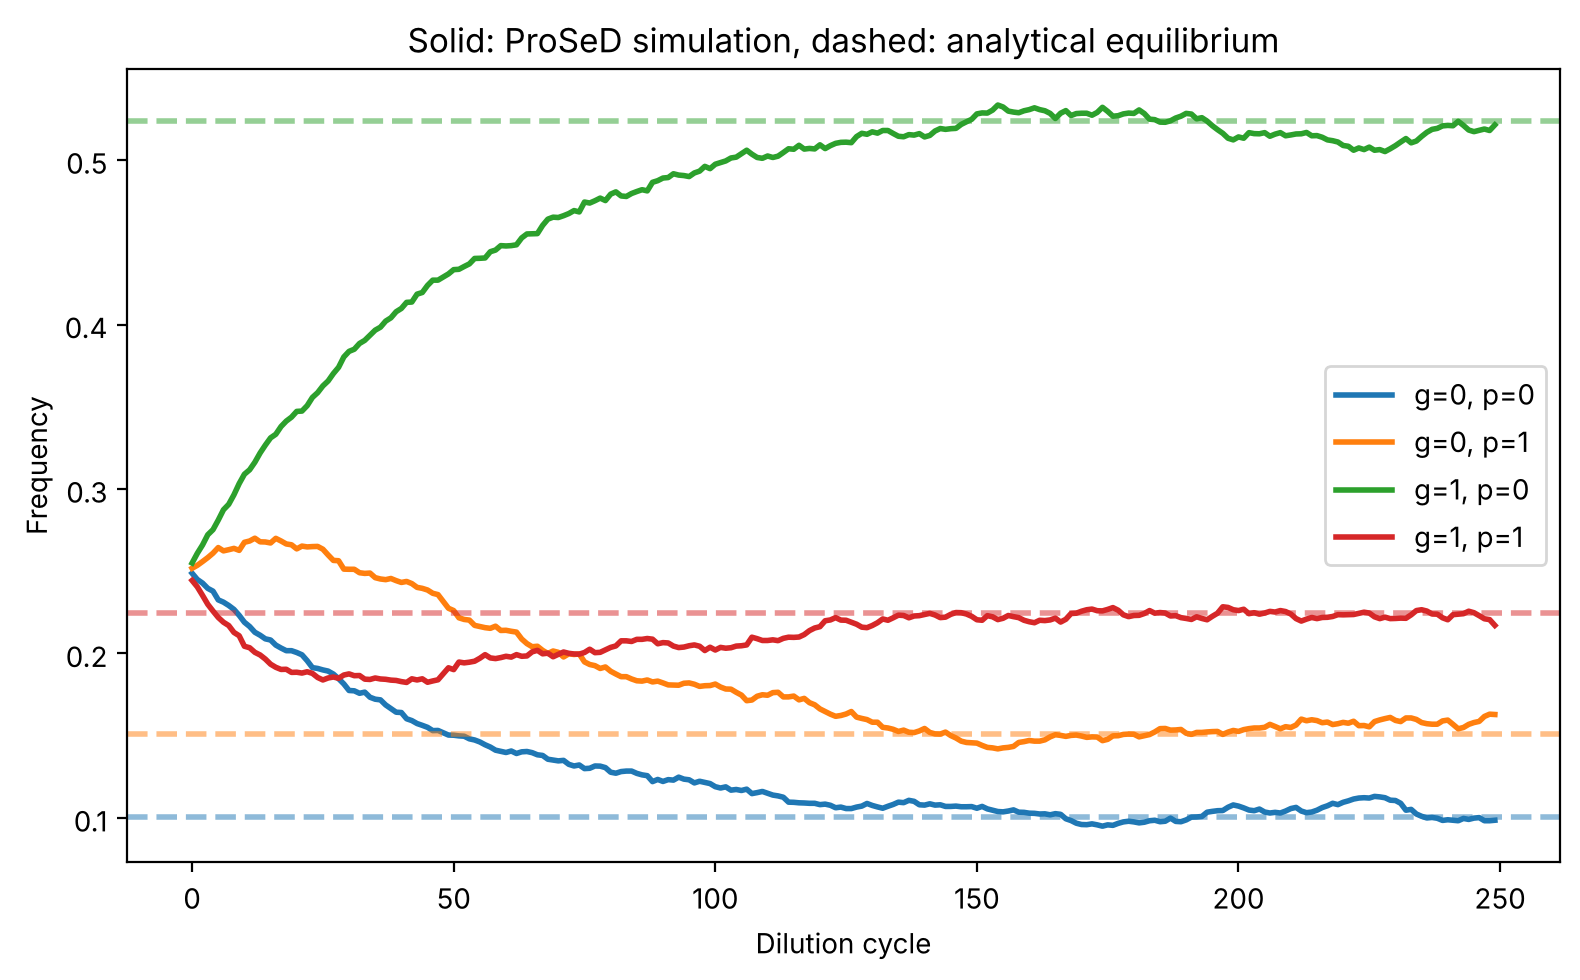

max |sim - theory| = 0.003238672118200725


In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

for g in range(V):
    for p in range(Q):
        line, = ax.plot(freq_timeseries[g, p], lw=2, label=f'g={g}, p={p}')
        ax.axhline(f_eq[g*Q + p], color=line.get_color(), ls='--', lw=2, alpha=0.5)

ax.set_xlabel('Dilution cycle')
ax.set_ylabel('Frequency')
ax.set_title('ProSeD simulation vs. analytical equilibrium')
ax.legend()
plt.tight_layout()
plt.show()

sim_avg = freq_timeseries[:, :, -100:].mean(axis=2).flatten() # average over last 100 timesteps
print('max |sim - theory| =', np.max(np.abs(sim_avg - f_eq)))